# 01 · Exploring the GTFS feeds

Goal: understand the Long Beach Transit (LBT) feed for one representative weekday before turning it into a graph in Week 2.

- **Feed:** Long Beach Transit (small, fast to iterate on). Metro bus/rail appear only for comparison.
- **Analysis date:** Wednesday 2026-11-04 (chosen in `notes/gtfs_notes.md`).
- **Loader:** `transitshock.load_gtfs.load_feed`, which filters every table to that day's active service.

In [1]:
from pathlib import Path

import folium
import matplotlib.pyplot as plt
import pandas as pd

from transitshock.load_gtfs import load_feed

# Find the repo root so paths work no matter where Jupyter was started.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
RAW = ROOT / "data" / "raw"
FIGURES = ROOT / "figures"
FIGURES.mkdir(exist_ok=True)

DATE = "20261104"
data = load_feed(RAW / "lbt", DATE)
stops, routes, trips, stop_times = (data[k] for k in ["stops", "routes", "trips", "stop_times"])

## 1. How big is the network on one weekday?

In [2]:
served_stops = stop_times["stop_id"].nunique()
summary = pd.Series({
    "stops in stops.txt": len(stops),
    "stops served on this day": served_stops,
    "routes": len(routes),
    "routes running on this day": trips["route_id"].nunique(),
    "trips": len(trips),
    "stop_times rows": len(stop_times),
})
summary

stops in stops.txt             1873
stops served on this day       1853
routes                           35
routes running on this day       34
trips                          1914
stop_times rows               91696
dtype: int64

## 2. Which modes run? (`route_type`)

In [3]:
ROUTE_TYPES = {0: "Light rail", 1: "Subway", 2: "Rail", 3: "Bus"}
routes["route_type"].astype(int).map(ROUTE_TYPES).value_counts()

route_type
Bus    35
Name: count, dtype: int64

LBT is all bus. For contrast, Metro rail mixes light rail and subway:

In [4]:
rail = load_feed(RAW / "metro_rail", DATE)
rail["routes"].assign(mode=rail["routes"]["route_type"].astype(int).map(ROUTE_TYPES))[
    ["route_long_name", "mode", "route_color"]
]

,route_long_name,mode,route_color
0,Metro A Line,Light rail,0072BC
1,Metro B Line,Subway,EB131B
2,Metro C Line,Light rail,58A738
3,Metro E Line,Light rail,FDB913
4,Metro K Line,Light rail,E56DB1
5,Metro D Line,Subway,A05DA5


## 3. Stations vs. stops (`location_type`)

Only `location_type = 0` rows are served by vehicles. Stations (`1`) group platforms, which we'll need to merge in Week 2.

In [5]:
LOCATION_TYPES = {0: "Stop / platform", 1: "Station", 2: "Entrance", 3: "Generic node", 4: "Boarding area"}
pd.DataFrame({
    "LBT": stops["location_type"].map(LOCATION_TYPES).value_counts(),
    "Metro rail": rail["stops"]["location_type"].map(LOCATION_TYPES).value_counts(),
}).fillna(0).astype(int)

,LBT,Metro rail
location_type,,
Entrance,0,238
Station,0,111
Stop / platform,1873,114


In [6]:
# Entrances also have a parent_station, so keep only platforms (location_type 0).
rail_stops = rail["stops"]
rail_platforms = rail_stops[(rail_stops["location_type"] == 0) & (rail_stops["parent_station"] != "")]
platforms_per_station = rail_platforms.groupby("parent_station").size()
print(f"Metro rail: {len(rail_platforms)} platforms in {len(platforms_per_station)} stations")
platforms_per_station.value_counts().sort_index().rename_axis("platforms per station").rename("stations")

Metro rail: 114 platforms in 111 stations


platforms per station
1    108
2      3
Name: stations, dtype: int64

## 4. Busiest stops (trips per day)

In [7]:
stop_freq = stop_times.groupby("stop_id").size().rename("trips_per_day")
routes_per_stop = (
    stop_times.merge(trips[["trip_id", "route_id"]], on="trip_id")
    .groupby("stop_id")["route_id"].nunique().rename("routes")
)
busiest = (
    stops.set_index("stop_id")[["stop_name"]]
    .join([stop_freq, routes_per_stop], how="inner")
    .sort_values("trips_per_day", ascending=False)
)
busiest.head(10)

,stop_name,trips_per_day,routes
stop_id,,,
1026,Beach Dr & W Campus N,327,9
4011,1st & Shelter G S,265,2
4135,Artesia Station Bay 3,263,2
4010,Long Beach Blvd & 3rd SE,262,9
1025,W Campus & Library East Side,249,9
1027,Beach Dr & Dorms N,249,9
0520,7th & Channel SE,249,9
4012,1st & Shelter H S,243,6
0364,Pacific & 3rd SW,230,9


## 5. How long are trips? (stops per trip, duration)

,stops,minutes
count,1914.0,1914.0
mean,47.9,52.8
std,18.4,20.1
min,5.0,14.0
25%,32.0,40.0
50%,48.0,54.0
75%,64.0,66.0
max,87.0,115.0


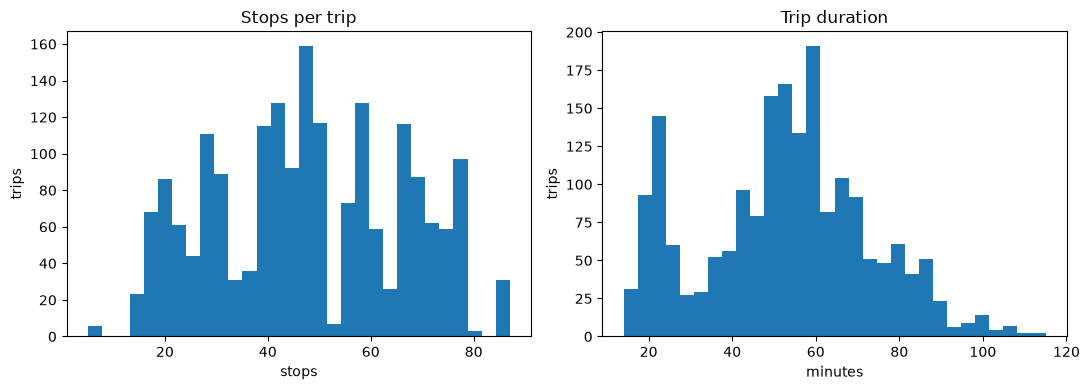

In [8]:
per_trip = stop_times.groupby("trip_id").agg(
    stops=("stop_id", "size"),
    start=("departure_s", "min"),
    end=("arrival_s", "max"),
)
per_trip["minutes"] = (per_trip["end"] - per_trip["start"]) / 60

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(per_trip["stops"], bins=30)
axes[0].set(title="Stops per trip", xlabel="stops", ylabel="trips")
axes[1].hist(per_trip["minutes"], bins=30)
axes[1].set(title="Trip duration", xlabel="minutes", ylabel="trips")
fig.tight_layout()
fig.savefig(FIGURES / "lbt_trip_lengths.png", dpi=150)
per_trip[["stops", "minutes"]].describe().round(1)

## 6. When does service run? (trips starting per hour)

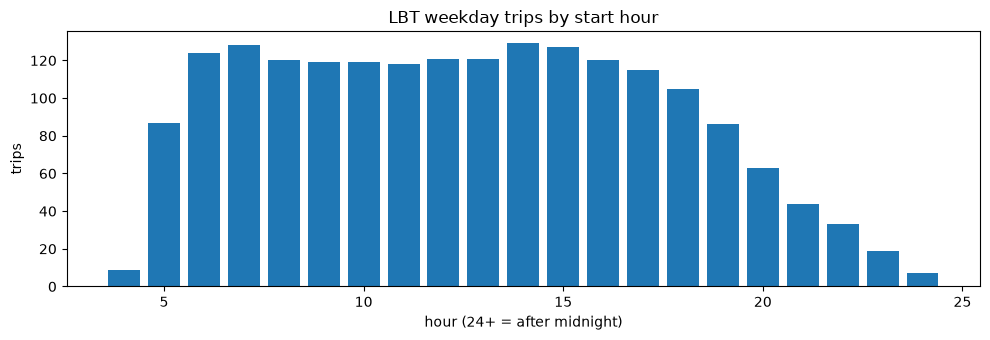

In [9]:
start_hour = (per_trip["start"] // 3600).astype(int)
counts = start_hour.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.bar(counts.index, counts.values)
ax.set(title="LBT weekday trips by start hour", xlabel="hour (24+ = after midnight)", ylabel="trips")
fig.tight_layout()
fig.savefig(FIGURES / "lbt_trips_by_hour.png", dpi=150)

## 7. Where are the stops? (map sized by trips per day)

Saved to `figures/lbt_stop_frequency_map.html`; open it in a browser to explore.

In [10]:
mapped = stops.merge(stop_freq, left_on="stop_id", right_index=True, how="inner")
max_trips = mapped["trips_per_day"].max()

m = folium.Map(location=[mapped["stop_lat"].mean(), mapped["stop_lon"].mean()], zoom_start=12)
for row in mapped.itertuples():
    folium.CircleMarker(
        [row.stop_lat, row.stop_lon],
        radius=2 + 8 * row.trips_per_day / max_trips,
        popup=f"{row.stop_name}: {row.trips_per_day} trips",
        color="#D62028", fill=True, fill_opacity=0.6, weight=0,
    ).add_to(m)
m.save(FIGURES / "lbt_stop_frequency_map.html")
# Run `m` in a cell to view the map inline; left out to keep the notebook small.
print(f"Mapped {len(mapped)} stops")

Mapped 1853 stops


## 8. Data quality checks

In [11]:
served = set(stop_times["stop_id"])
checks = pd.Series({
    "duplicate stop_ids": stops["stop_id"].duplicated().sum(),
    "stops missing coordinates": stops[["stop_lat", "stop_lon"]].isna().any(axis=1).sum(),
    "stop_times referencing unknown stops": len(served - set(stops["stop_id"])),
    "stops never served on this day": len(set(stops["stop_id"]) - served),
    "blank arrival times": stop_times["arrival_s"].isna().sum(),
    "after-midnight stop_times (>= 24:00)": (stop_times["arrival_s"] >= 24 * 3600).sum(),
    "approximate times (timepoint = 0)": (stop_times["timepoint"] == 0).sum(),
})
checks

duplicate stop_ids                          0
stops missing coordinates                   0
stop_times referencing unknown stops        0
stops never served on this day             20
blank arrival times                         0
after-midnight stop_times (>= 24:00)      365
approximate times (timepoint = 0)       78422
dtype: int64

In [12]:
# Within a trip, time should never go backwards.
gaps = stop_times.groupby("trip_id")["arrival_s"].diff()
print("negative stop-to-stop times:", int((gaps < 0).sum()))
print("zero-second stop-to-stop times:", int((gaps == 0).sum()))
gaps.describe().round(1)

negative stop-to-stop times: 0
zero-second stop-to-stop times: 485


count    89782.0
mean        67.5
std         53.0
min          0.0
25%         43.0
50%         60.0
75%         80.0
max       5160.0
Name: arrival_s, dtype: float64

In [13]:
# Which segments take more than 15 minutes?
long_gaps = stop_times.assign(gap_min=gaps / 60)[gaps > 15 * 60]
long_gaps.merge(trips[["trip_id", "route_id"]], on="trip_id").merge(
    stops[["stop_id", "stop_name"]], on="stop_id"
)[["route_id", "trip_id", "stop_sequence", "stop_name", "arrival_time", "gap_min"]]

,route_id,trip_id,stop_sequence,stop_name,arrival_time,gap_min
0,405,10794878,2,WIllow Station & 27th St,06:10:00,20.0
1,405,10794878,3,Kinross / Lot 36,07:28:00,78.0
2,405,10794879,2,WIllow Station & 27th St,07:10:00,20.0
3,405,10794879,3,Kinross / Lot 36,08:28:00,78.0
4,405,10794880,4,WIllow Station & 27th St,18:05:00,86.0
5,405,10794880,5,Long Beach Airport & Donald Douglas Dr NB,18:25:00,20.0
6,405,10794881,4,WIllow Station & 27th St,19:00:00,81.0
7,405,10794881,5,Long Beach Airport & Donald Douglas Dr NB,19:20:00,20.0
8,405,10795436,2,WIllow Station & 27th St,05:37:00,20.0
9,405,10795436,3,Kinross / Lot 36,06:28:00,51.0


In [14]:
routes.loc[routes["route_id"] == "405", ["route_id", "route_long_name"]]

,route_id,route_long_name
24,405,UCLA Westwood Express


## Findings

**Size (Wed 2026-11-04):** 1,914 trips on 34 of 35 routes serve 1,853 of 1,873 stops, giving 91,696 `stop_times` rows. Route 37 ("Passport") has no Wednesday service, and 20 stops go unserved that day. Unserved stops shouldn't become graph nodes.

**Modes:** LBT is 100% bus. Metro rail has 4 light-rail and 2 subway lines. In Metro rail's `stops.txt`, 114 platforms sit under 111 stations (108 stations have one platform, 3 have two), alongside 238 entrances. In Week 2, merge platforms into their station and drop entrances.

**Hubs:** The busiest stops are CSULB (Beach Dr & W Campus N, 327 trips/day), the downtown Long Beach transit mall (1st & Shelter, Long Beach Blvd & 3rd, Pacific & 3rd), and Artesia Station. Downtown stops are served by up to 9 routes. These are the obvious candidates for targeted-attack tests in Week 3.

**Trips:** The median trip has 48 stops and lasts 54 minutes (range 5–87 stops, 14–115 minutes).

**Service profile:** Service starts around 4–5 AM, stays flat at about 115–130 trips/hour from 6 AM to 5 PM, and tapers after 6 PM. There's no strong rush-hour peak, so a single all-day graph is a reasonable first model.

**Data quality:**
- No duplicate IDs, no missing coordinates, no orphan stop references, no blank or backwards times.
- 365 rows are after midnight, which the parser handles.
- 86% of times are interpolated (`timepoint = 0`), so edge weights are schedule estimates.
- 485 consecutive-stop pairs are 0 seconds apart: different stops, scheduled at the same minute. To avoid zero-weight edges in Week 2, set a small minimum travel time (for example 15 s).
- The median stop-to-stop time is 60 s. The only segments over 15 minutes are on route 405 (UCLA Westwood Express), which runs 78–86 minutes nonstop between Long Beach and Westwood. These are real freeway segments, not errors. They'll be long, high-weight edges that connect the network to a far-away cluster, so they're worth checking in the resilience analysis.

**Next (Week 2):** build the stop graph from consecutive `stop_times` pairs with median travel-time weights, merge rail platforms into stations, and add walking-transfer edges.